# Drug Review Sentiment Analysis (NLP)

**Business Question:** Can patient reviews help us identify positive and negative experiences with medications and understand which side effects are frequently mentioned in negative reviews?

**Objective:** Build a Natural Language Processing (NLP) model to classify patient drug reviews into positive and negative sentiment and explore commonly mentioned side effects across medical conditions.

**Data:** [drugsCom_raw.zip](https://archive.ics.uci.edu/ml/machine-learning-databases/00462/drugsCom_raw.zip) (43 MB) from UCI. Unzip it into `data/` (see `data/README.md`).

**Tools:** Python, Pandas, Scikit-learn, TF-IDF, Logistic Regression, Naive Bayes, Matplotlib and Seaborn.



## 1. Load and clean

In [1]:
import html                 # turns codes like &#039; back into normal characters
from pathlib import Path    # finds files in a folder
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def load(name):
    """Read one review file from data/, whatever its extension."""
    path = next(Path('data').glob(f'{name}.*'))   # .tsv in most copies, .csv in some
    return pd.read_csv(path, sep='\t' if path.suffix == '.tsv' else ',')   # .tsv = tab-separated

def prepare(df):
    """Clean the reviews and add the sentiment label."""
    df = df.copy()
    # Fix &#039; and similar codes, then strip quote marks and spaces from both ends
    df['review'] = df['review'].astype(str).map(html.unescape).str.strip('" ')   # fixes &#039; etc.
    df = df[~df['condition'].fillna('').str.contains('</span>')]   # scraping junk in condition
    df = df[(df['rating'] >= 7) | (df['rating'] <= 4)]             # drop neutral 5-6
    df['label'] = (df['rating'] >= 7).astype(int)                  # 1 = positive, 0 = negative
    return df.drop_duplicates('review')   # the same review text often appears more than once

train = prepare(load('drugsComTrain_raw'))
test = prepare(load('drugsComTest_raw'))
test = test[~test['review'].isin(set(train['review']))]   # same review is often posted for brand and generic

print(len(train), len(test))
train['label'].value_counts(normalize=True)   # share of positive (1) and negative (0) reviews

102134 14900


label
1    0.727955
0    0.272045
Name: proportion, dtype: float64

### Data Cleaning and Preparation

The following preprocessing steps were performed:

- Decoded HTML entities and cleaned review text.
- Removed invalid condition entries.
- Excluded ratings of 5 and 6 to focus on clear positive and negative sentiment.
- Assigned sentiment labels:
  - Ratings 1–4: Negative (0)
  - Ratings 7–10: Positive (1)
- Removed duplicate review texts.
- Removed test reviews that also appeared in the training dataset.

The original task of predicting ratings was converted into a binary sentiment classification problem.

After preprocessing, the training dataset contained 182,134 reviews and the test dataset contained 14,980 reviews.

## 2. Explore

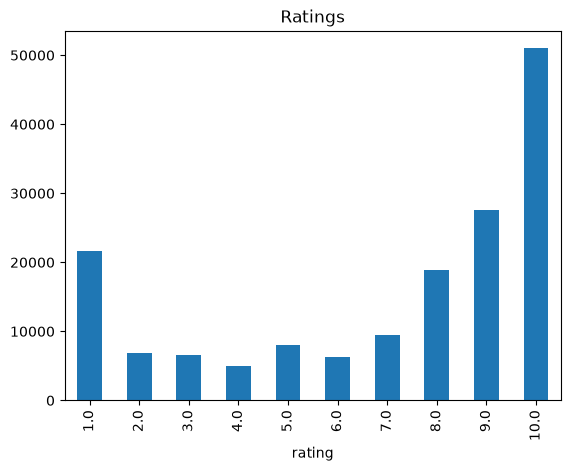

condition
Birth Control      15870
Depression          5697
Pain                4156
Anxiety             4048
Acne                3619
Bipolar Disorde     2654
Insomnia            2601
Weight Loss         2461
Obesity             2250
ADHD                2000
Name: count, dtype: int64


label
0    78.0
1    86.0
Name: words, dtype: float64

In [2]:
# How many reviews gave each star rating (1-10), before cleaning
load('drugsComTrain_raw')['rating'].value_counts().sort_index().plot(kind='bar', title='Ratings')
plt.show()
print(train['condition'].value_counts().head(10))   # the 10 most-reviewed conditions
# Median review length in words, for negative (0) and positive (1) reviews
train.assign(words=train['review'].str.split().str.len()).groupby('label')['words'].median()

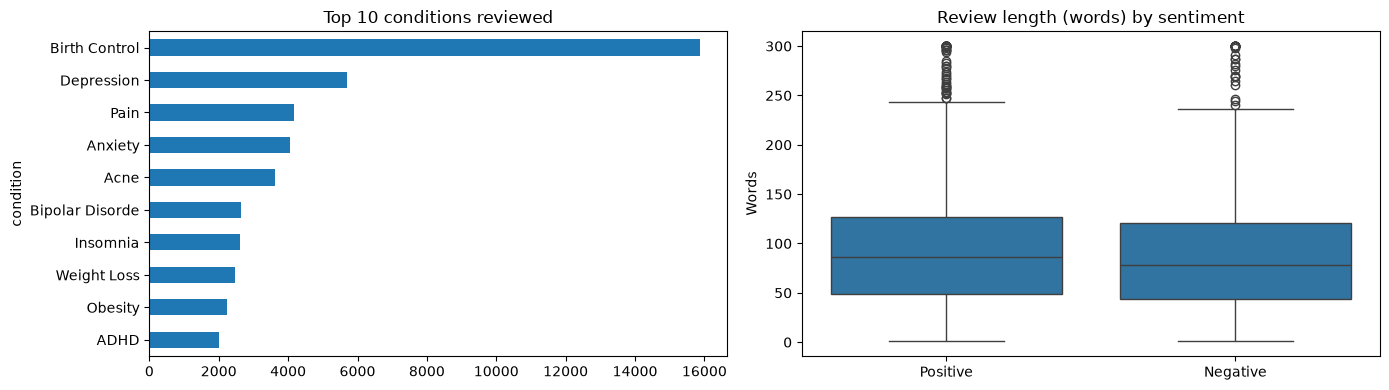

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))   # two charts side by side

# Left: the 10 most-reviewed conditions as horizontal bars, biggest at the top
train['condition'].value_counts().head(10).sort_values().plot(kind='barh', ax=axes[0],
                                                             title='Top 10 conditions reviewed')

# Right: review length by sentiment as box plots (box = middle half of reviews, line = median)
words = train['review'].str.split().str.len().clip(upper=300)   # cap very long reviews
sns.boxplot(x=train['label'].map({1: 'Positive', 0: 'Negative'}), y=words, ax=axes[1])
axes[1].set_title('Review length (words) by sentiment')
axes[1].set_xlabel('')
axes[1].set_ylabel('Words')

plt.tight_layout()
plt.savefig('images/eda.png', dpi=150)

### Exploratory Data Analysis – Key Findings

- Rating 10 was the most frequent rating, followed by ratings 9 and 1.
- Birth Control was the most frequently reviewed medical condition.
- Depression, Pain, Anxiety and Acne were also among the most reviewed conditions.
- The median review length was approximately 78 words for negative reviews and 86 words for positive reviews.

These observations provide an understanding of the dataset's rating distribution, frequently reviewed conditions and patient review patterns.

## 3. Baseline, then the real model

The grid search fits 12 models and takes a few minutes.

Naive Bayes macro F1: 0.667
{'clf__C': 16}
              precision    recall  f1-score   support

           0      0.758     0.843     0.799      4040
           1      0.939     0.900     0.919     10860

    accuracy                          0.885     14900
   macro avg      0.849     0.872     0.859     14900
weighted avg      0.890     0.885     0.886     14900



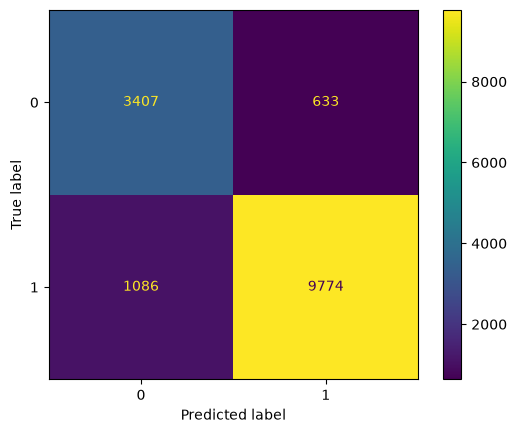

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, f1_score, ConfusionMatrixDisplay

# TF-IDF turns each review into numbers: one column per word or word pair, weighted so that
# words that are frequent in this review but rare across all reviews count most.
#   ngram_range=(1, 2): single words and word pairs ('not good' means the opposite of 'good')
#   min_df=5: ignore words found in fewer than 5 reviews (typos, names)
#   max_features: keep the 200,000 most frequent words and pairs
#   sublinear_tf: a word used 10 times doesn't count 10 times as much
# No stop-word removal: it would delete 'not' and 'no', which flip the sentiment
tfidf = dict(ngram_range=(1, 2), min_df=5, max_features=200_000, sublinear_tf=True)

# Baseline: Naive Bayes, a simple and fast text classifier
nb = Pipeline([('tfidf', TfidfVectorizer(**tfidf)), ('clf', MultinomialNB())])
nb.fit(train['review'], train['label'])
print('Naive Bayes macro F1:', round(f1_score(test['label'], nb.predict(test['review']), average='macro'), 3))

# Main model: Logistic Regression. class_weight='balanced' gives the smaller negative class equal weight.
lr = Pipeline([('tfidf', TfidfVectorizer(**tfidf)),
               ('clf', LogisticRegression(max_iter=2000, class_weight='balanced'))])
# Try 4 values of C (higher C = less regularisation), each scored with 3-fold cross-validation
grid = GridSearchCV(lr, {'clf__C': [1, 4, 16, 64]}, cv=3, scoring='f1_macro', n_jobs=-1)
grid.fit(train['review'], train['label'])
print(grid.best_params_)

# Score the tuned model once on the test reviews
pred = grid.predict(test['review'])
print(classification_report(test['label'], pred, digits=3))   # precision, recall and F1 per class
ConfusionMatrixDisplay.from_predictions(test['label'], pred)   # counts of right and wrong predictions
plt.savefig('images/confusion_matrix.png', dpi=150)

### Model Performance and Evaluation

Two machine learning models were evaluated:

| Model | Macro F1-score |
|---|---:|
| Multinomial Naive Bayes | 0.667 |
| Logistic Regression | 0.859 |

Logistic Regression outperformed the Naive Bayes baseline.

The Logistic Regression model was tuned using GridSearchCV with 3-fold cross-validation and macro F1-score as the evaluation metric.

**Best hyperparameter:** C = 16

#### Final Test Results

- Accuracy: 88.5%
- Macro F1-score: 0.859
- Negative sentiment F1-score: 0.799
- Positive sentiment F1-score: 0.919

The confusion matrix shows:

- 3,407 negative reviews correctly classified.
- 9,774 positive reviews correctly classified.
- 633 negative reviews incorrectly classified as positive.
- 1,086 positive reviews incorrectly classified as negative.

The model performed better on positive reviews than negative reviews.

## 4. Look inside the model

In [5]:
best = grid.best_estimator_
vocab = best.named_steps['tfidf'].get_feature_names_out()   # the word or pair behind each column
coef = best.named_steps['clf'].coef_[0]   # one weight per word: + pushes positive, - pushes negative
# argsort() lists positions from the lowest weight to the highest
print('Most positive:', list(vocab[coef.argsort()[-20:][::-1]]))   # last 20, highest first
print('Most negative:', list(vocab[coef.argsort()[:20]]))          # first 20

# Read some mistakes: they make good interview stories
errors = test[pred != test['label']].sample(5, random_state=1)   # 5 random misclassified reviews
for _, r in errors.iterrows():
    print(r['rating'], r['review'][:300], '\n')   # star rating and the first 300 characters

Most positive: ['love', 'amazing', 'miracle', 'saved', 'excellent', 'love it', 'great', 'love this', 'wonderful', 'works', 'would recommend', 'highly recommend', 'awesome', 'years', 'saved my', 'overall', 'very effective', 'no side', 'changed my', 'wonders']
Most negative: ['not recommend', 'not worth', 'disappointed', 'no relief', 'don recommend', 'useless', 'wouldn recommend', 'no improvement', 'worse', 'never again', 'nothing for', 'not', 'only good', 'not working', 'any better', 'ruined', 'no difference', 'waste', 'does nothing', 'worst']
10.0 I received a chemical burn from trying a home care for inner thigh bleaching. To make a long story short i my doctor took a look the next day and was shocked with the fleshy skin and a gyno recommended for me to use this stuff. I wasn't able to walk for a week because of the burns and my doctor beli 

10.0 I was given Atenolol for rapid heartbeat and high blood pressure, I was on recruiting duty and had started these problems, plus I started 

### Model Interpretation

The Logistic Regression model assigns coefficients to words and word combinations.

- Positive coefficients push predictions towards positive sentiment.
- Negative coefficients push predictions towards negative sentiment.

Some strong positive indicators included words such as love, amazing, excellent, effective and wonderful.

Some strong negative indicators included phrases such as not recommend, horrible, disappointed, no relief and useless.

The model also examined incorrectly classified reviews to understand where it struggled to identify the correct sentiment.

These words represent patterns learned by the model and do not establish the medical effectiveness or safety of a drug.

## 5. Side effects behind negative reviews

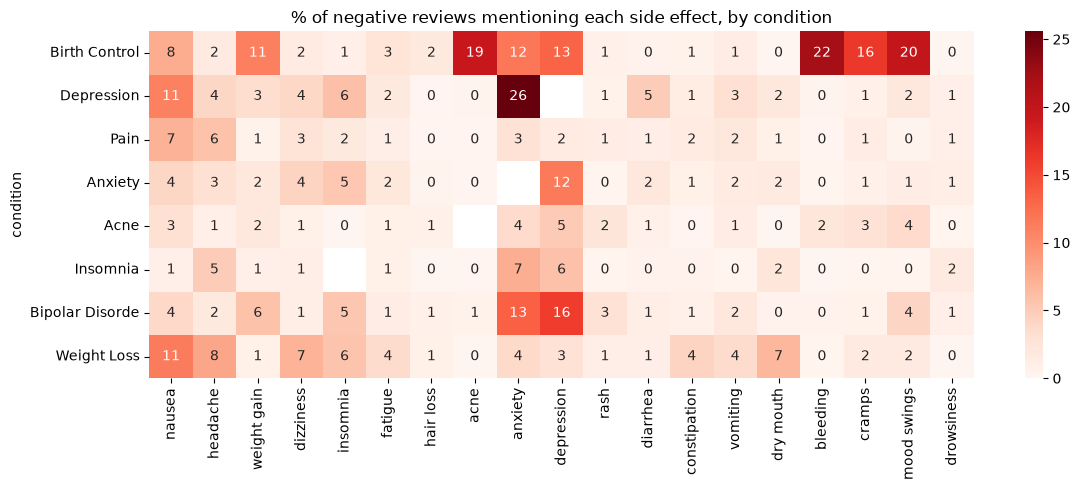

In [6]:
# Common side effects to look for, in lower case (the reviews are lower-cased below)
side_effects = ['nausea', 'headache', 'weight gain', 'dizziness', 'insomnia', 'fatigue', 'hair loss',
                'acne', 'anxiety', 'depression', 'rash', 'diarrhea', 'constipation', 'vomiting',
                'dry mouth', 'bleeding', 'cramps', 'mood swings', 'drowsiness']

reviews = pd.concat([train, test])                                  # every cleaned review
negative = reviews[reviews['label'] == 0]                           # only the unhappy ones
top_conditions = reviews['condition'].value_counts().head(8).index  # the 8 most-reviewed conditions

# For each condition and side effect: the % of negative reviews that mention the side effect.
# \b marks a word boundary, so 'rash' doesn't match inside 'crash'.
heat = pd.DataFrame({
    se: [100 * negative.loc[negative['condition'] == c, 'review'].str.lower().str.contains(rf'\b{se}\b').mean()
         for c in top_conditions]
    for se in side_effects
}, index=top_conditions)

# People treated for anxiety write "anxiety": that's the condition, not a side effect, so blank those cells
for c in heat.index:
    for se in heat.columns:
        if se in c.lower():
            heat.loc[c, se] = None

plt.figure(figsize=(12, 5))
sns.heatmap(heat, annot=True, fmt='.0f', cmap='Reds')   # darker red = mentioned more often
plt.title('% of negative reviews mentioning each side effect, by condition')
plt.tight_layout()
plt.savefig('images/side_effects_heatmap.png', dpi=150)

### Side-Effect Mention Analysis

The heatmap examines the percentage of negative reviews mentioning selected side-effect keywords across the eight most-reviewed medical conditions.

- Rows represent medical conditions.
- Columns represent selected side-effect keywords.
- Cell values represent the percentage of negative reviews within each condition mentioning a particular keyword.
- Darker shades indicate a higher percentage of mentions.

This analysis provides an overview of commonly discussed patient experiences.

**Important:** These are keyword-based mentions from patient reviews. They do not establish that a medication caused a particular side effect.

## 6. Conclusion

This project demonstrates how Natural Language Processing can be used to analyze patient drug reviews and classify their sentiment.

The Logistic Regression model using TF-IDF features achieved a macro F1-score of 0.859, outperforming the Multinomial Naive Bayes baseline of 0.667.

The analysis also identified words associated with positive and negative sentiment and explored commonly mentioned side-effect keywords across medical conditions.

### Limitations

1. Star ratings are an imperfect substitute for actual sentiment.
2. Positive reviews are more common than negative reviews.
3. TF-IDF models may struggle with sarcasm and context.
4. Keyword matching may miss synonyms and negation.
5. Online reviews may not represent the wider patient population.
6. Review mentions do not establish that a medication caused a side effect.
